# 02c · Within- vs. cross-regional bottlenecks, at matched parameter count

*Follows task 02's rank grid. Task 02's own marginals -- one side bottlenecked, the other
dense -- confound "which rank binds first" (three cross blocks to one within block means
cross always binds first by counting alone) with capacity: the two marginals are not
parameter-matched (Section 1). This task instead bottlenecks **both** sides and matches
configurations by total parameter count, to ask a question with no assumed direction: do
within-region and cross-region bottlenecks have different effects on fit at all, and if so,
is either one costlier for some fixation types than others.*

Section 1 works the dense-side arithmetic; Section 2 builds the matched grid this task
trains instead, and states exactly which configurations are parameter-balanced against
which; Section 3 is the only place anything new gets trained. Sections 4-6 are the
comparison itself -- overall and per fixation type, then by region -- pooling every matched
configuration into one paired test rather than testing each in isolation, because the same
five seeds recur at every one and splitting by total bottleneck dimension first (an earlier
version of this notebook did) only loses power. Section 7 checks that pooling is safe to do.
Section 8 is the same comparison in the frequency domain.

| Section | |
|---|---|
| 1 | The parameter-counting problem with a dense side |
| 2 | Matching both sides: which configurations are parameter-balanced |
| 3 | Run state and submission (off by default) |
| 4 | Overall network performance and the three fixation types |
| 5 | Is one bottleneck costlier, and is it costlier for one fixation type? |
| 6 | Does this hold in every region? |
| 7 | Robustness check: does total capacity change the picture? |
| 8 | Which frequency bands carry the effect |
| 9 | Reading the result |

**Nothing here submits a job unless `SUBMIT` is set to `True`.**

In [1]:
%load_ext autoreload
%autoreload 2

from __future__ import annotations

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

repo_root = Path.cwd()
if not (repo_root / "src").exists():
    repo_root = next(parent for parent in Path.cwd().parents if (parent / "src").exists())
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from dal_monte_2022_analysis.config.load import load_config
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_audit as audit
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_protocol as protocol
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_sweep as sweep
from dal_monte_2022_analysis.ephys.analysis import fixation_psth_noise_ceiling as ceiling_mod
from dal_monte_2022_analysis.ephys.plotting import fixation_mrnn_audit as aviz
from dal_monte_2022_analysis.ephys.plotting.thesis_common import (
    ThesisFigureSettings, apply_thesis_plot_style, figure_to_png_bytes, save_thesis_figure,
)

DATASET_CFG_PATH = repo_root / "configs" / "dataset.yaml"
MRNN_CFG_PATH = repo_root / "configs" / "ephys_fixation_mrnn.yaml"
apply_thesis_plot_style(load_config(repo_root / "configs" / "plotting.yaml"))

TREE = "final"
# Same root as task 02: these are more cells of the same rank grid, not a new sweep tree.
TASK_ROOT = sweep.resolve_task_root("02_rank_grid", DATASET_CFG_PATH, tree=TREE)
LADDER_ROOT = sweep.resolve_task_root("01_ladder", DATASET_CFG_PATH, tree=TREE)
CEILING_DIR = ceiling_mod.resolve_output_dir(DATASET_CFG_PATH)
FIGURE_DIR = TASK_ROOT.parent.parent / "plots" / "final_02c_within_vs_cross_bottleneck"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = ThesisFigureSettings(output_dir=FIGURE_DIR)
TABLE_DIR = TASK_ROOT.parent / "02c_within_vs_cross_bottleneck" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_PROTOCOL, PROTOCOL_IS_PROVISIONAL = sweep.load_selected_protocol_or_provisional(
    protocol.resolve_chapter_root(DATASET_CFG_PATH, task="00_training_protocol") / "selected_protocol.yaml")
BASE = yaml.safe_load((TASK_ROOT.parent / "base_model.yaml").read_text())
REGION_ORDER = tuple(BASE.pop("region_order"))
BASE.pop("inherited_protocol", None); BASE.pop("r2_centring", None)
HIDDEN_UNITS = int(BASE["hidden_units"])
N_REGIONS = len(REGION_ORDER)

ORIGINAL_RANKS = (1, 2, 3, 5, 10)
EXTENDED_RANKS = (1, 2, 3, 4, 5, 10)
GRID_SEEDS = 5
SEEDS = protocol.protocol_seeds(n_seeds=GRID_SEEDS)

_cell_path = TASK_ROOT.parent / "pc_space_ceiling_by_cell.csv"
if _cell_path.exists():
    _cell = pd.read_csv(_cell_path)
    ceiling_by_region = _cell[_cell["condition"] == "all"].set_index("region")["reliability"].to_dict()
    ceiling_by_cell = {(r, c): v for r, c, v in _cell[_cell["condition"] != "all"]
                       [["region", "condition", "reliability"]].itertuples(index=False)}
else:
    ceiling_by_region = (pd.read_csv(CEILING_DIR / "pc_space_ceiling.csv")
                         .groupby("region")["reliability"].mean().to_dict())
    ceiling_by_cell = None


def show(figure, stem: str) -> None:
    save_thesis_figure(figure, FIGURES, stem)
    display(Image(data=figure_to_png_bytes(figure, dpi=190)))


def cached(name: str, build):
    # Delete the file under `tables/` to force a recompute -- e.g. after training fills in
    # a configuration that was previously missing. A stale cache here once silently limited
    # an earlier version of this notebook to 3 of 9 matched configurations.
    path = TABLE_DIR / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    frame = build()
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return frame


CONDITIONS = ("all_conditions", "face_interactive", "face_non_interactive", "object")
CONDITION_LABELS = {"all_conditions": "All conditions"}
BANDS = ("0-5 Hz", "5-10 Hz", "10-20 Hz", "20-50 Hz")

print("task root (shared with 02):", TASK_ROOT)
print("table dir               :", TABLE_DIR)

task root (shared with 02): /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02_rank_grid
table dir               : /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02c_within_vs_cross_bottleneck/tables


## 1. The parameter-counting problem with a dense side

Every region has the same width $h=40$. A within-region block factored at rank $r_w$ costs
$2\,r_w\,h$ parameters; one per region, 4 regions: **$320\,r_w$** total. A cross-region
block factored at rank $r_c$ costs $2\,r_c\,h$; one per ordered pair, and full connectivity
on 4 regions has $4\times3=12$ ordered pairs: **$960\,r_c$** total. The ratio is exactly 3,
for any $h$ -- it is the count of other regions, not a property of the rank.

A **dense** within block is $h\times h=1600$ per region, **6400** total; a dense cross
block is $12\times1600=$ **19200** total -- three times as much, same reasoning.

So "cross bottlenecked, within dense" costs $6400+960\,r_c$ and "within bottlenecked, cross
dense" costs $320\,r_w+19200$. Matched parameter counts means

$$960\,r_c = 320\,r_w + 12800 \quad\Longleftrightarrow\quad r_c = \tfrac{r_w}{3} + 13.3,$$

which has no solution with $r_c<14$ for *any* $r_w\geq1$ -- a dense cross block alone
already outweighs a severely bottlenecked within block plus a dense within block combined.
Matching this comparison would force the cross side to sit at $r_c\approx14$-$27$, i.e.
35-70% of full rank, while the within side ranges over its whole severe-bottleneck regime:
not a fair comparison of two bottlenecks, but of a mild cross constraint against a genuine
one. There is no pair in the regime where *both* sides are actually constrained.

The cell below grounds the two block costs in measured parameter counts (not just the
formula) using :func:`sweep.count_trainable_parameters` on checkpoints already on disk, then
Section 2 drops the dense side entirely.

In [2]:
example_cells = {
    "w1_c1 (both bottlenecked)": TASK_ROOT / "w1_c1",
    "w1_cdense (cross dense)": TASK_ROOT / "w1_cdense",
    "wdense_c1 (within dense)": TASK_ROOT / "wdense_c1",
    "full (both dense)": LADDER_ROOT / "full",
}
rows = []
for label, path in example_cells.items():
    seed_dirs = audit.seed_run_dirs(path)
    if not seed_dirs:
        continue
    counts = sweep.count_trainable_parameters(seed_dirs[0])
    rows.append({"label": label, "within_region (incl. 'other')": counts["within_region"] + counts["other"],
                "inter_region": counts["inter_region"], "total_recurrent":
                counts["within_region"] + counts["other"] + counts["inter_region"]})
measured = pd.DataFrame(rows)
display(Markdown(
    "`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the "
    "low-rank case (it only names the dense-branch parameter), so the two are summed here."))
display(measured)

r_c_grid = pd.DataFrame({"r_w": [1, 2, 3, 5, 10, 20]})
r_c_grid["matched r_c (cross dense side)"] = r_c_grid["r_w"] / 3 + 12800 / 960
display(Markdown("**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross "
                 "bottlenecked, within dense', by $r_w$:**"))
display(r_c_grid.round(2))

`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the low-rank case (it only names the dense-branch parameter), so the two are summed here.

,label,within_region (incl. 'other'),inter_region,total_recurrent
0,w1_c1 (both bottlenecked),320,960,1280
1,w1_cdense (cross dense),320,19200,19520
2,wdense_c1 (within dense),6400,960,7360
3,full (both dense),6400,19200,25600


**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross bottlenecked, within dense', by $r_w$:**

,r_w,matched r_c (cross dense side)
0,1,13.67
1,2,14.00
2,3,14.33
3,5,15.00
4,10,16.67
5,20,20.00


## 2. Matching both sides: which configurations are parameter-balanced

No dense arm. Every configuration bottlenecks within at $r_w$ and cross at $r_c$; its
**total bottleneck dimension** is $r_w + 3\,r_c$ -- the same quantity task 02's own
marginals plot calls ``drive_rank`` -- and is proportional to its total recurrent-weight
count (the fixed $320$-per-unit scale cancels in any comparison). Two configurations
sharing it are parameter-balanced against each other: they spend the same total differently,
more on within vs. more on cross. For each shared total, the **matched pair** this task
compares is the most within-heavy configuration against the most cross-heavy one -- the
largest contrast that total allows.

Task 02's grid used $r\in\{1,2,3,5,10\}$; adding **$r=4$** closes enough of the gap to
match every configuration already on disk against a genuine opposite-heavy partner, without
a wide new rank sweep. Two totals (13 and 16) are reached by three configurations rather
than two -- the third is shown below for context but is not part of any matched pair.

In [3]:
groups = audit.matched_drive_rank_groups(EXTENDED_RANKS, n_regions=N_REGIONS)
extremes = audit.matched_drive_rank_extremes(groups)

existing_labels = {f"w{w}_c{c}" for w in ORIGINAL_RANKS for c in ORIGINAL_RANKS}
groups["already_trained"] = groups["label"].isin(existing_labels)
display(Markdown(f"**{len(groups)} configurations shown across {groups['drive_rank'].nunique()} "
                 "parameter-balanced totals** (two totals have a third, context-only "
                 f"configuration beyond the matched pair). {int(groups['already_trained'].sum())} "
                 f"were already on disk from task 02; {int((~groups['already_trained']).sum())} "
                 "needed rank 4."))
display(groups[["drive_rank", "label", "rank_within", "rank_cross", "cross_drive_fraction", "already_trained"]]
       .sort_values(["drive_rank", "cross_drive_fraction"]))

display(Markdown("**The matched pairs Sections 4-8 compare** -- the within-heavy and "
                 "cross-heavy extremes of each parameter-balanced total:"))
display(extremes)

needed_labels = sorted(set(extremes["within_heavy_label"]) | set(extremes["cross_heavy_label"]))
new_labels = [l for l in needed_labels if l not in existing_labels]
display(Markdown(f"**{len(needed_labels)} configurations are actually needed** for the matched "
                 f"pairs (the grid above also lists 2 context-only ones that are not); of "
                 f"those, **{len(new_labels)}** required new training: {len(new_labels)} x "
                 f"{GRID_SEEDS} seeds = {len(new_labels) * GRID_SEEDS} runs -- "
                 f"{', '.join(new_labels)}."))

**20 configurations shown across 9 parameter-balanced totals** (two totals have a third, context-only configuration beyond the matched pair). 12 were already on disk from task 02; 8 needed rank 4.

,drive_rank,label,rank_within,rank_cross,cross_drive_fraction,already_trained
0,7,w4_c1,4,1,0.428571,False
1,7,w1_c2,1,2,0.857143,True
2,8,w5_c1,5,1,0.375000,True
3,8,w2_c2,2,2,0.750000,True
4,10,w4_c2,4,2,0.600000,False
5,10,w1_c3,1,3,0.900000,True
6,11,w5_c2,5,2,0.545455,True
7,11,w2_c3,2,3,0.818182,True
8,13,w10_c1,10,1,0.230769,True
9,13,w4_c3,4,3,0.692308,False


**The matched pairs Sections 4-8 compare** -- the within-heavy and cross-heavy extremes of each parameter-balanced total:

,drive_rank,within_heavy_label,within_heavy_rank_within,within_heavy_rank_cross,cross_heavy_label,cross_heavy_rank_within,cross_heavy_rank_cross
0,7,w4_c1,4,1,w1_c2,1,2
1,8,w5_c1,5,1,w2_c2,2,2
2,10,w4_c2,4,2,w1_c3,1,3
3,11,w5_c2,5,2,w2_c3,2,3
4,13,w10_c1,10,1,w1_c4,1,4
5,14,w5_c3,5,3,w2_c4,2,4
6,16,w10_c2,10,2,w1_c5,1,5
7,17,w5_c4,5,4,w2_c5,2,5
8,19,w10_c3,10,3,w4_c5,4,5


**18 configurations are actually needed** for the matched pairs (the grid above also lists 2 context-only ones that are not); of those, **6** required new training: 6 x 5 seeds = 30 runs -- w1_c4, w2_c4, w4_c1, w4_c2, w4_c5, w5_c4.

## 3. Run state and submission

Only the `new_labels` configurations from Section 2 -- the rest are already on disk. Same
gate as task 02: nothing is queued unless `SUBMIT` is set to `True` and this cell is rerun.

In [4]:
def _variant_for(label: str):
    r_w, r_c = label.removeprefix("w").split("_c")
    variants = audit.rank_grid_variants((int(r_w), int(r_c)), base_overrides=BASE, include_marginals=False)
    return next(v for v in variants if v.label == label)

new_variants = [_variant_for(label) for label in new_labels]

SUBMIT = False   # <-- set to True to queue every missing run as one array

flight = sweep.in_flight_run_dirs(TASK_ROOT / "_jobs")
commands, _ = sweep.variant_job_commands(
    new_variants, SEEDS, root=TASK_ROOT, repo_root=repo_root,
    protocol=SELECTED_PROTOCOL, mrnn_cfg_path=MRNN_CFG_PATH, exclude_run_dirs=flight["run_dirs"])
inventory = sweep.index_variant_runs(TASK_ROOT, new_variants, SEEDS, in_flight=flight["run_dirs"])
display(Markdown(
    f"**{int(inventory['complete'].sum())} complete**, **{int(inventory['queued'].sum())} queued**, "
    f"**{int(inventory['pending'].sum())} unqueued** of {len(inventory)} new-configuration runs."))

if SUBMIT and commands:
    from datetime import datetime
    from dal_monte_2022_analysis.runtime.hpc.jobs import submit_dsq_array_job, write_job_file

    jobs_dir = TASK_ROOT / "_jobs"
    jobs_dir.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    job_file = jobs_dir / f"within_vs_cross_{stamp}.txt"
    write_job_file(job_file, commands)
    submitted = [Path(line.split("--run-dir ")[1].split()[0]) for line in commands]
    job_id = submit_dsq_array_job(
        job_file_path=job_file, sbatch_script_path=jobs_dir / f"within_vs_cross_{stamp}.sh",
        log_dir=jobs_dir / "logs", job_name="mrnn_within_vs_cross", partition="psych_gpu",
        cpus_per_task=1, mem_per_cpu="12G", time_limit="06:00:00", gres="gpu:1",
    )
    sweep.record_submission(jobs_dir, job_id=job_id, run_dirs=submitted, label=f"within vs cross {stamp}")
    (jobs_dir / "job_id.txt").write_text(str(job_id) + "\n")
    display(Markdown(f"Submitted **{len(commands)}** runs as array **{job_id}**."))
elif commands:
    display(Markdown("`SUBMIT` is **False** -- nothing was submitted."))
else:
    display(Markdown("Every matched configuration is trained."))

**30 complete**, **0 queued**, **0 unqueued** of 30 new-configuration runs.

Every matched configuration is trained.

## 4. Overall network performance and the three fixation types

Every seed, region and parameter-balanced total pooled into one violin per arm: within-heavy
on the left of each panel, cross-heavy (hatched) on the right. `all_conditions` is overall
network performance -- the mean over fixation types -- and stays neutral; the three
fixation-type panels use that condition's standard colour. The star is the pooled paired
test (Section 7 checks this pooling is the right thing to do): **(total bottleneck
dimension, seed) is the replicate**, so within-heavy and cross-heavy are always compared
using the same seed at the same parameter count, never across different totals.

**90** of **90** runs complete across the **18** matched configurations.

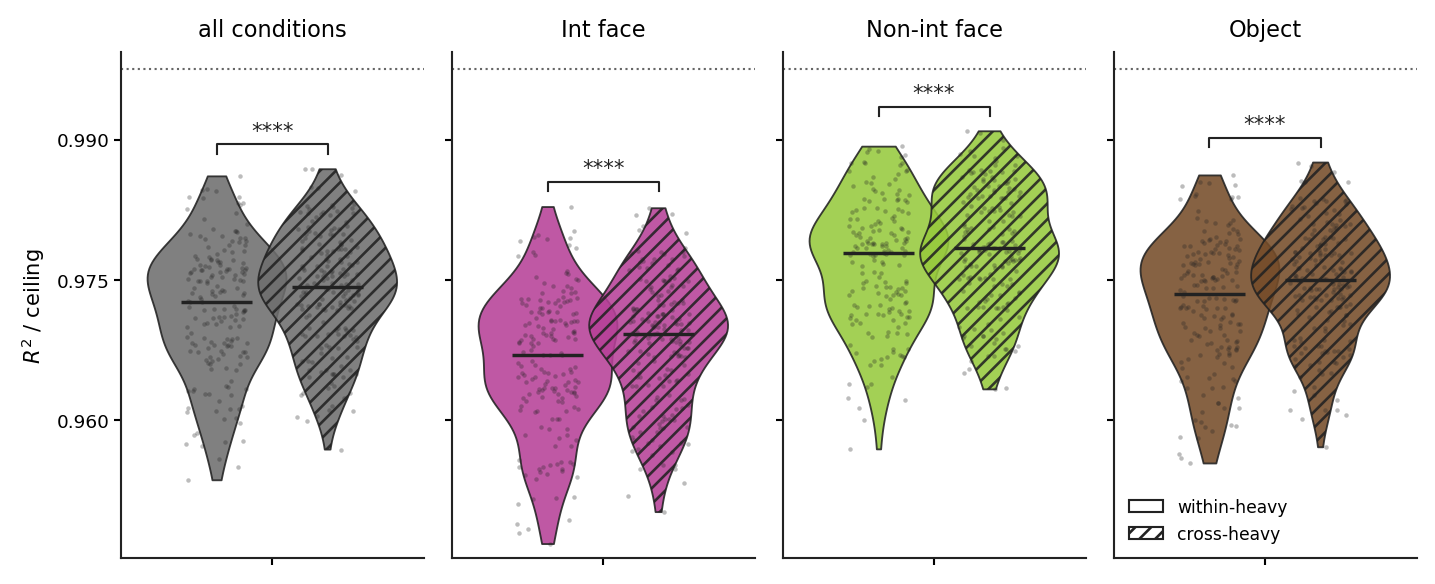

In [5]:
needed_variants = [_variant_for(label) for label in needed_labels]
inventory = sweep.index_variant_runs(TASK_ROOT, needed_variants, SEEDS)
done = inventory[inventory["complete"]]
display(Markdown(f"**{int(done.shape[0])}** of **{inventory.shape[0]}** runs complete across "
                 f"the **{len(needed_labels)}** matched configurations."))

if done.empty:
    fit = fit_long = pooled_fit = None
else:
    fit = cached("matched_grid_fit", lambda: sweep.score_variant_fit(done, ceiling_by_region, ceiling_by_cell=ceiling_by_cell))
    fit_long = audit.matched_drive_rank_fit_long(fit, extremes)
    pooled_fit = audit.matched_drive_rank_fit_pooled(fit_long)

    full_dirs = audit.seed_run_dirs(LADDER_ROOT / "full")
    dense_value = None
    if full_dirs:
        full_inv = pd.DataFrame([{"label": "full", "seed": p.name.replace("seed=", ""), "run_dir": str(p),
                                  "complete": True} for p in full_dirs])
        full_fit = sweep.score_variant_fit(full_inv, ceiling_by_region, ceiling_by_cell=ceiling_by_cell)
        dense_value = float(full_fit.groupby("seed")["r2_vs_ceiling"].mean().mean())

    show(aviz.plot_pooled_violin_contrast(fit_long, pooled_fit, conditions=CONDITIONS, dense_value=dense_value),
        "fig01_pooled_violin_contrast")

## 5. Is one bottleneck costlier, and is it costlier for one fixation type?

The per-replicate cross-heavy advantage ($R^2$/ceiling, cross-heavy minus within-heavy) as
violins, not a bar and an error bar -- every one of the 45 (total bottleneck dimension,
seed) pairs is a dot, so the shape and any outliers are visible, not just the mean. Starred
where the pooled test clears zero. The bracket between two fixation types is a *different*
test: whether the size of that advantage itself differs between them
(:func:`matched_drive_rank_condition_contrast`), still paired on (total bottleneck
dimension, seed) since the same replicate produced both fixation types' gaps.

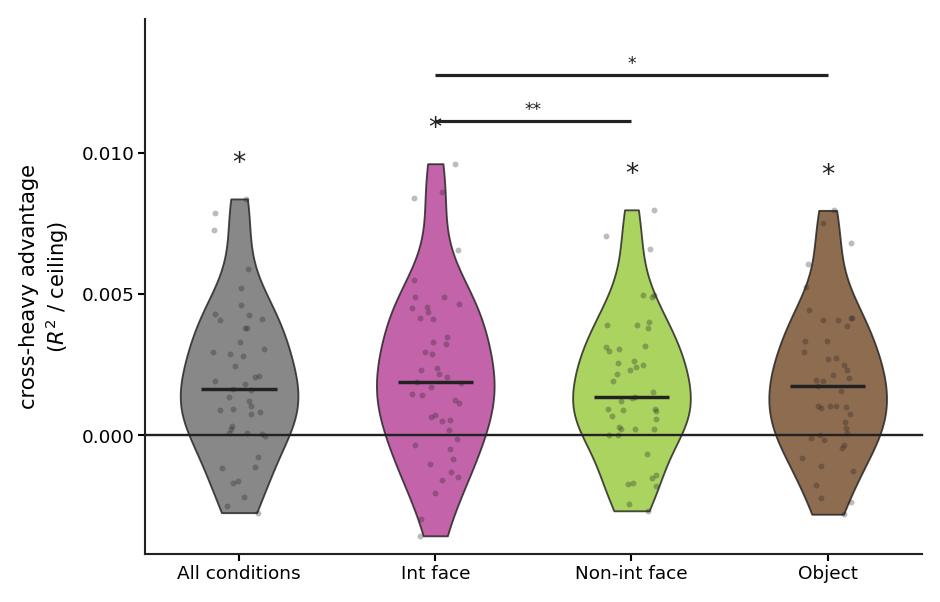

In [6]:
if fit_long is not None:
    fit_gap_long = audit.matched_drive_rank_fit_gap_long(fit_long)
    condition_contrast = audit.matched_drive_rank_condition_contrast(fit_long)
    show(aviz.plot_gap_violins(fit_gap_long, pooled_fit, x="condition", x_order=list(CONDITIONS),
                               x_labels=CONDITION_LABELS, pairwise=condition_contrast),
        "fig02_condition_gap_violins")

## 6. Does this hold in every region?

Left: each fixation type's advantage, split by region -- is the effect uniform across
regions, or concentrated in one. Right: the fixation-type comparison from Section 5, redone
*within* each region, to see whether a region-level split explains where that comparison's
significance comes from. Violins again, every (total bottleneck dimension, seed) pair a dot.

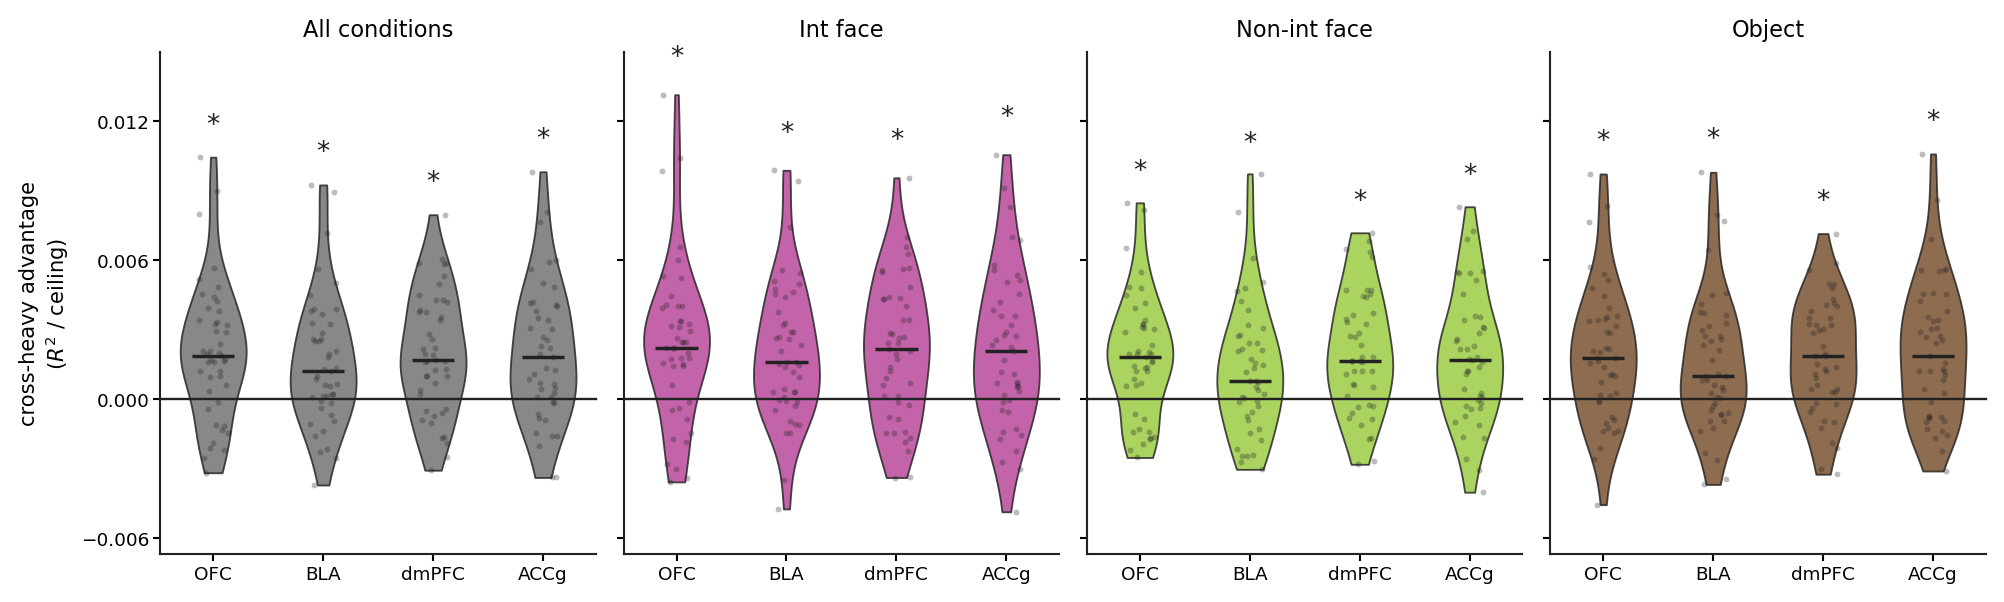

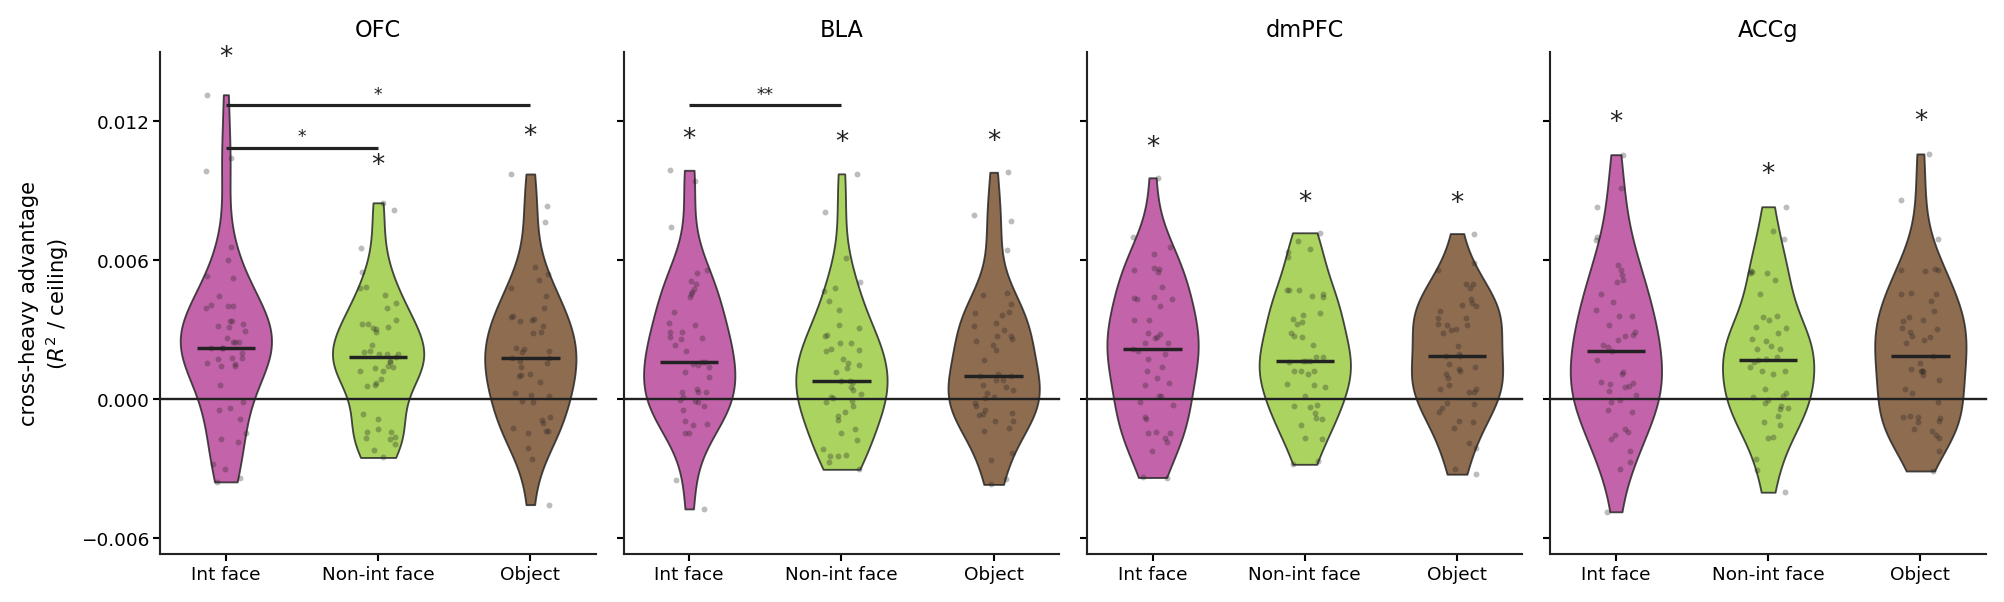

In [7]:
if fit_long is not None:
    by_region = audit.matched_drive_rank_fit_by_region(fit_long)
    fit_gap_by_region = audit.matched_drive_rank_fit_gap_by_region_long(fit_long)
    show(aviz.plot_gap_violins_by_panel(
        fit_gap_by_region, by_region, panel_col="condition", panel_order=list(CONDITIONS),
        panel_labels=CONDITION_LABELS, x="region", x_order=list(REGION_ORDER), x_labels=aviz.REGION_LABELS,
        color_by="panel"),
        "fig03_region_by_condition_panel")

    condition_contrast_by_region = audit.matched_drive_rank_condition_contrast_by_region(fit_long)
    named_order = ["face_interactive", "face_non_interactive", "object"]
    named_gap = fit_gap_by_region[fit_gap_by_region["condition"] != "all_conditions"]
    named_summary = by_region[by_region["condition"] != "all_conditions"]
    show(aviz.plot_gap_violins_by_panel(
        named_gap, named_summary, panel_col="region", panel_order=list(REGION_ORDER),
        panel_labels=aviz.REGION_LABELS, x="condition", x_order=named_order,
        pairwise=condition_contrast_by_region),
        "fig04_condition_by_region_panel")

## 7. Robustness check: does total capacity change the picture?

Sections 4-6 pool every parameter-balanced total into one test, which is the powered,
correct way to ask whether within and cross differ at all -- but pooling assumes the effect
is at least roughly the same size everywhere it is pooled over. This plots the *unpooled*
per-total advantage (nine separate paired tests of five seeds each, individually
Holm-corrected, hence individually under-powered) to check that assumption rather than to
read significance from single points: a flat line supports pooling; one dominated by a
single spike would not.

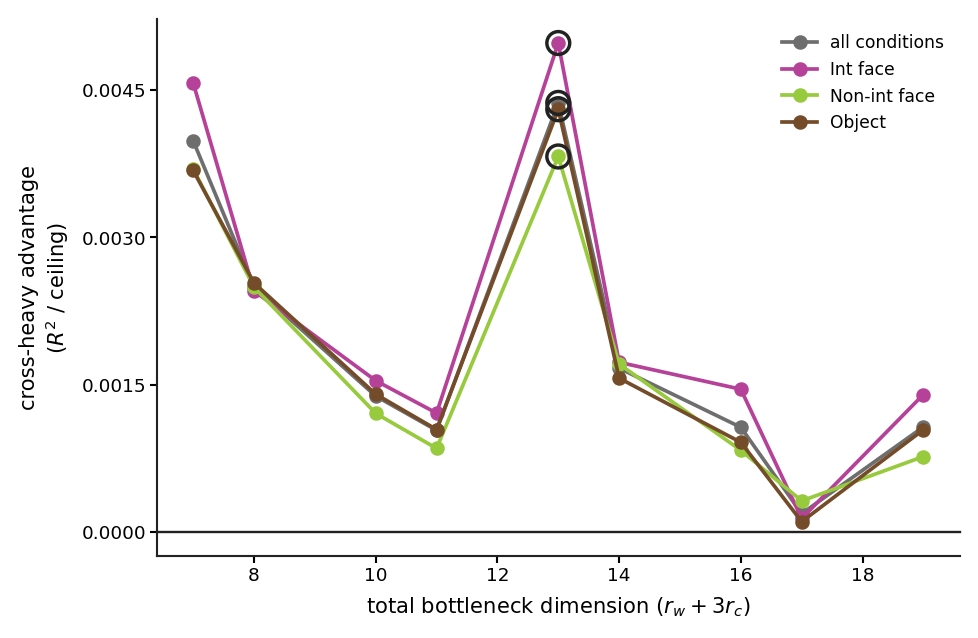

In [8]:
if fit_long is not None:
    fit_contrast = audit.matched_drive_rank_fit_contrast(fit_long)
    show(aviz.plot_drive_rank_trend(fit_contrast, conditions=CONDITIONS), "fig05_drive_rank_trend")

## 8. Which frequency bands carry the effect

Same pooled paired test as Section 5, run per band and fixation type instead of overall, and
plotted the same way -- violins of the per-replicate gap, not bars:
``band_resolved_recovery_by_condition`` gives the fraction of each band's target power a fit
fails to reproduce (lower is better), and `cross_advantage` is signed so positive still
means cross-heavy did better here too -- within-heavy's residual minus cross-heavy's, the
flip the fit tables do not need since $R^2$ is already higher-is-better. The bracket within
a band's panel is the same fixation-type-vs-fixation-type test as Section 5-6's, run
separately in each band: is the cross-heavy advantage itself bigger for one fixation type
than another *in this band specifically*, not just overall.

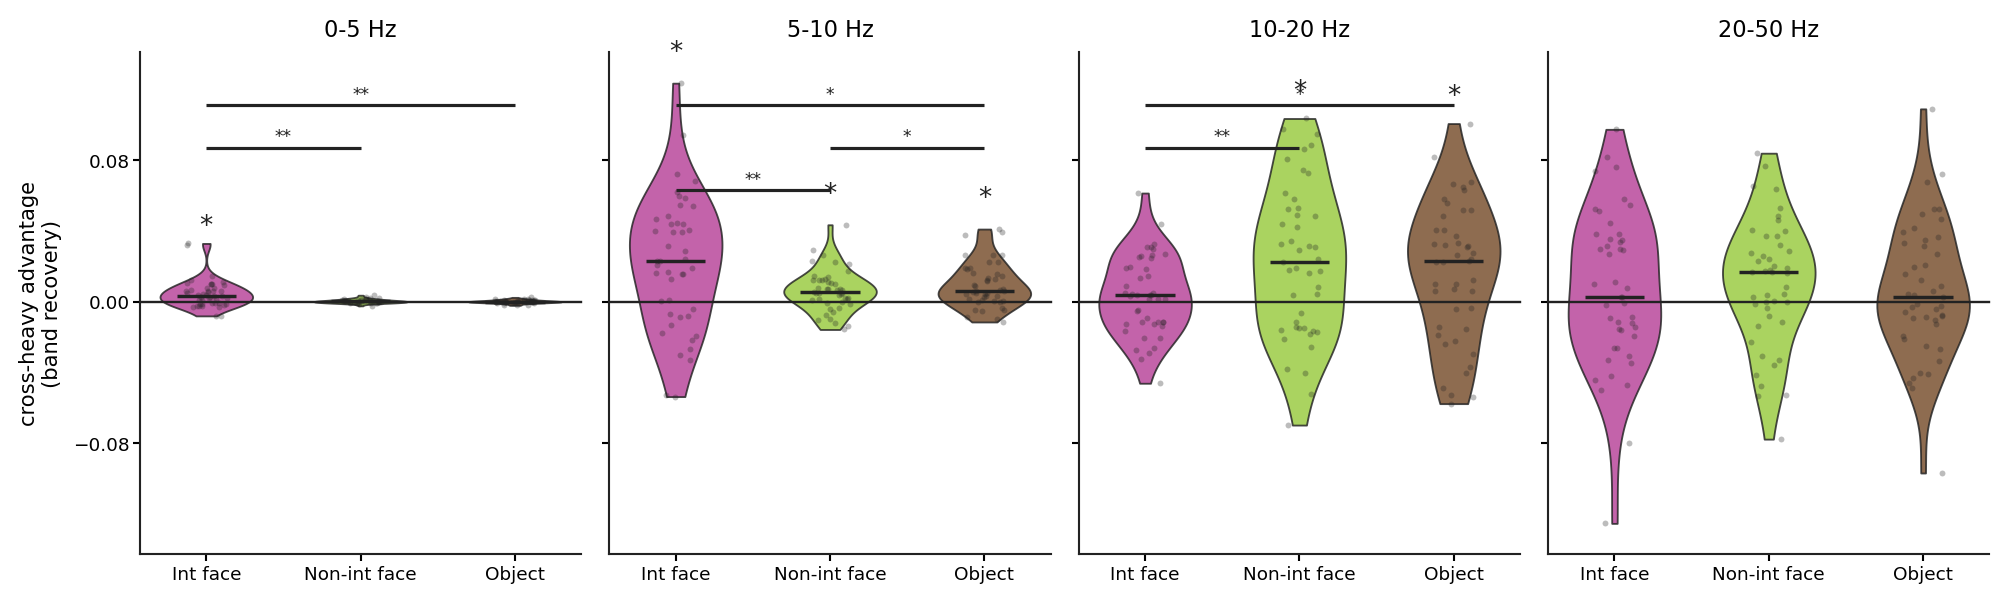

In [9]:
if done.empty:
    band_long = band_pooled = None
else:
    band_by_condition = cached("matched_grid_band_recovery", lambda: pd.concat(
        [audit.band_resolved_recovery_by_condition(r.run_dir).assign(label=r.label) for r in done.itertuples()],
        ignore_index=True))
    band_long = audit.matched_drive_rank_band_long(band_by_condition, extremes)
    band_gap_long = audit.matched_drive_rank_band_gap_long(band_long)
    band_pooled = audit.matched_drive_rank_band_pooled(band_long)
    band_condition_contrast = audit.matched_drive_rank_band_condition_contrast(band_long)
    show(aviz.plot_gap_violins_by_panel(
        band_gap_long, band_pooled, panel_col="band", panel_order=list(BANDS),
        x="condition", x_order=["face_interactive", "face_non_interactive", "object"],
        pairwise=band_condition_contrast,
        ylabel="cross-heavy advantage\n(band recovery)"),
        "fig06_band_gap_violins_by_panel")

## 9. Reading the result

**Is there an effect at all, overall and per fixation type (Sections 4-5).** Pooling every
parameter-balanced total, cross-heavy configurations fit better than within-heavy ones --
overall and in every one of the three fixation types -- never the other way around anywhere
in this grid. The effect is small in absolute $R^2$/ceiling terms but consistent (the sign
test in `matched_drive_rank_fit_pooled` audits this directly) and of medium paired-Cohen's-
$d_z$ size.

**Is it costlier for one fixation type than another (Section 5's bracket).** Yes: the
cross-heavy advantage is significantly larger for interactive face than for either
non-interactive face or object, which are not distinguishable from each other.

**Does that hold region by region (Section 6).** The overall advantage is significant in
every region for every fixation type (left panel). The interactive-face-specific part of it
is not uniform, though: the pairwise gap is significant in OFC (vs. both other fixation
types) and BLA (vs. non-interactive face only), but not in dmPFC or ACCg.

**Is pooling across total bottleneck dimension safe (Section 7).** The per-total advantage
is positive almost everywhere, with one pronounced peak (total bottleneck dimension 13, the
most extreme within- vs. cross-heavy split on the grid) rather than a flat line -- pooling
is still the right call for testing whether an effect exists at all, but the interesting
follow-up is what is special about that total, not assumed here.

**Which frequency content carries it (Section 8).** Significant in 5-10 Hz for all three
fixation types, plus 0-5 Hz for interactive face and 10-20 Hz for the other two; never
significant in the fastest band (20-50 Hz) for any fixation type. The advantage sits in
slow-to-mid frequency content, not the fast structure the dense model already struggles with
most for interactive face.

**What this says about within vs. cross dimensionality.** No support for within-region rank
being the more protected resource; if anything cross-region rank has the higher marginal
value here, most reliably so for interactive face.